# Notebook 2: CARE analysis (runs on the laptop)

Reads the per-patient statistics file and answers: **do the intervals contain the true ratio as often as promised, and how wide are they?**

- Uses `data/stats.npz` (from Kaggle) if it exists, otherwise `data/synthetic_stats.npz` (fake data with a known answer).
- All the logic lives in the `care/` package; this notebook only calls it and shows results.
- Kernel: select the `care` environment (Python 3.12) at the top right of VS Code.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from care import stats as S, intervals as I, baselines as B, metrics as M, experiment as E

(ROOT / "results").mkdir(exist_ok=True)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Bootstrap": "#888780", "Conformal": "#BA7517", "CARE (V-Bias)": "#0F6E56", "CARE (ECE)": "#534AB7"}

## 1. Load and check the statistics

In [2]:
REAL, SYNTH = ROOT / "data" / "stats.npz", ROOT / "data" / "synthetic_stats.npz"
STATS_PATH = REAL if REAL.exists() else SYNTH
IS_SYNTHETIC = STATS_PATH == SYNTH
stats = S.load_stats(STATS_PATH)
S.check_stats(stats)            # raises an error if the file is malformed
print(f"Using {STATS_PATH.name}: {S.n_cases(stats)} patients", "(SYNTHETIC DATA)" if IS_SYNTHETIC else "(real data)")

summary = pd.DataFrame({
    "true ratio": S.true_ratio(stats),
    "predicted ratio": S.pred_ratio(stats),
    "tumour size (voxels)": stats["syB"],
    "|V-Bias| region A": np.abs(S.vbias(stats, "A")),
    "ECE region A": S.ece(stats, "A"),
})
summary.describe().T[["mean", "std", "min", "50%", "max"]]

Using stats.npz: 97 patients (real data)


,mean,std,min,50%,max
true ratio,1.980e-01,1.629e-01,1.360e-02,1.469e-01,0.729
predicted ratio,1.597e-01,1.381e-01,2.139e-04,1.186e-01,0.633
tumour size (voxels),1.043e+05,6.123e+04,1.010e+04,9.113e+04,263750.000
|V-Bias| region A,6.030e-04,9.618e-04,4.868e-07,2.938e-04,0.005
ECE region A,9.615e-04,1.050e-03,3.031e-05,6.077e-04,0.005


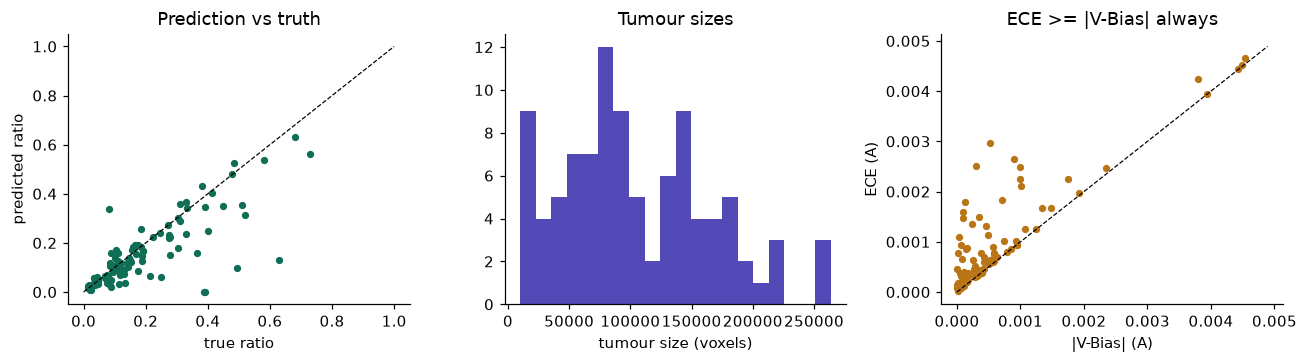

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].scatter(S.true_ratio(stats), S.pred_ratio(stats), s=14, color="#0F6E56")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set(xlabel="true ratio", ylabel="predicted ratio", title="Prediction vs truth")
ax[1].hist(stats["syB"], bins=20, color="#534AB7"); ax[1].set(xlabel="tumour size (voxels)", title="Tumour sizes")
ax[2].scatter(np.abs(S.vbias(stats, "A")), S.ece(stats, "A"), s=14, color="#BA7517")
lim = max(ax[2].get_xlim()[1], ax[2].get_ylim()[1]); ax[2].plot([0, lim], [0, lim], "k--", lw=0.8)
ax[2].set(xlabel="|V-Bias| (A)", ylabel="ECE (A)", title="ECE >= |V-Bias| always")
plt.tight_layout(); plt.savefig(ROOT / "results" / "sanity.png"); plt.show()

## 2. One split in detail: what CARE computes

Half of the patients are the **calibration set** (used to measure the network's calibration error), the other half is the **test set** (where we check the intervals).
`fit_care` returns `qA`, `qB` (quantiles of the calibration error) and `alpha`, `delta` (how the error budget is split between the estimation term and the calibration term).

In [4]:
LEVEL = 0.68
rng = np.random.default_rng(0)
perm = rng.permutation(S.n_cases(stats))
half = len(perm) // 2
cal, test = S.subset(stats, perm[:half]), S.subset(stats, perm[half:])
r_true = S.true_ratio(test)

params = {kind: I.fit_care(cal, LEVEL, kind) for kind in ("vbias", "ece")}
print(pd.DataFrame(params).T[["alpha", "delta", "qA", "qB"]])

lo, hi = I.predict(test, params["vbias"])
view = pd.DataFrame({"tumour size": test["syB"], "true r": r_true, "r_hat": S.pred_ratio(test), "lower": lo, "upper": hi,
                     "inside": (r_true >= lo) & (r_true <= hi)}).sort_values("tumour size")
view.head(8)

      alpha delta     qA     qB
vbias  0.02   0.3  0.001  0.001
ece    0.02   0.3  0.002  0.002


,tumour size,true r,r_hat,lower,upper,inside
35,10101.0,0.176,0.190,0.000e+00,1.000,True
44,10437.0,0.095,0.081,0.000e+00,1.000,True
32,12771.0,0.081,0.339,0.000e+00,1.000,True
10,18890.0,0.494,0.098,0.000e+00,1.000,True
9,20487.0,0.020,0.013,0.000e+00,1.000,True
48,23456.0,0.014,0.026,0.000e+00,0.694,True
4,28269.0,0.311,0.359,1.890e-04,1.000,True
12,39829.0,0.183,0.256,0.000e+00,0.805,True


## 3. Repeat over 100 random splits

One split of ~100 patients gives a noisy coverage. Repeating the random cal/test split 100 times gives a mean and a standard deviation. **Coverage** (target = the level) measures validity; **width** measures usefulness.

In [5]:
runs = E.run_repeated_splits(stats, n_repeats=100, level=LEVEL, seed=0)
table = E.summarize_runs(runs)
table.to_csv(ROOT / "results" / "coverage_table.csv")
table

,coverage_mean,width_mean,corr_mean,coverage_std,width_std,corr_std
method,,,,,,
Bootstrap,0.031,0.002,-0.416,0.018,1.461e-04,0.105
Conformal,0.665,0.090,0.238,0.102,1.253e-02,0.119
CARE (V-Bias),0.913,0.338,-0.852,0.038,5.218e-02,0.033
CARE (ECE),0.955,0.473,-0.871,0.025,6.017e-02,0.029


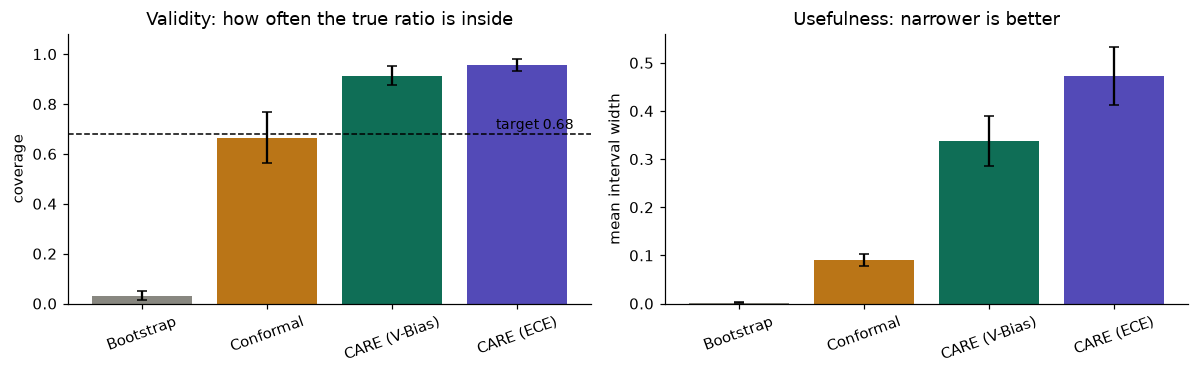

In [6]:
methods = list(table.index)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(methods, table["coverage_mean"], yerr=table["coverage_std"], color=[COLORS[m] for m in methods], capsize=3)
ax[0].axhline(LEVEL, color="k", ls="--", lw=1); ax[0].text(3.45, LEVEL + 0.02, f"target {LEVEL}", ha="right", fontsize=9)
ax[0].set(ylabel="coverage", title="Validity: how often the true ratio is inside", ylim=(0, 1.08))
ax[1].bar(methods, table["width_mean"], yerr=table["width_std"], color=[COLORS[m] for m in methods], capsize=3)
ax[1].set(ylabel="mean interval width", title="Usefulness: narrower is better")
for a in ax: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(ROOT / "results" / "coverage_width.png"); plt.show()

## 4. Adaptiveness: width versus tumour size

The paper's claim: CARE intervals are wider for small tumours and narrower for large ones, while conformal prediction gives the same width to everybody.

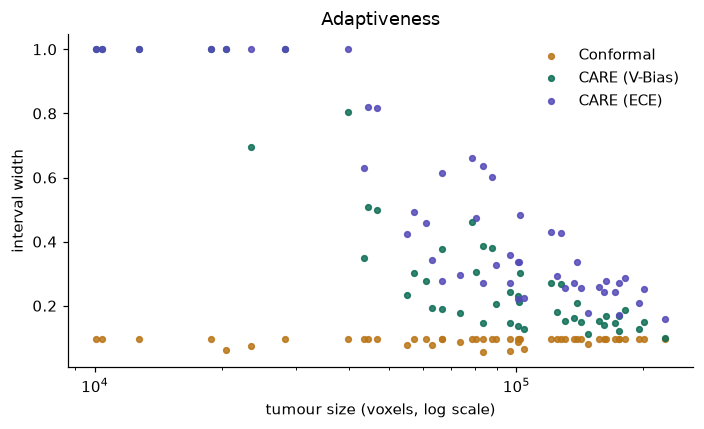

,small,medium,large
Conformal,0.091,0.088,0.096
CARE (V-Bias),0.613,0.245,0.157
CARE (ECE),0.757,0.389,0.256


In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for name, (l, h) in {"Conformal": B.conformal_predict(test, B.conformal_fit(cal, LEVEL)),
                     "CARE (V-Bias)": I.predict(test, params["vbias"]),
                     "CARE (ECE)": I.predict(test, params["ece"])}.items():
    ax.scatter(test["syB"], h - l, s=14, label=name, color=COLORS[name], alpha=0.85)
ax.set(xscale="log", xlabel="tumour size (voxels, log scale)", ylabel="interval width", title="Adaptiveness")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(ROOT / "results" / "adaptiveness.png"); plt.show()

pd.DataFrame({n: M.width_by_size_tertile(*p, test["syB"]) for n, p in
              {"Conformal": B.conformal_predict(test, B.conformal_fit(cal, LEVEL)),
               "CARE (V-Bias)": I.predict(test, params["vbias"]), "CARE (ECE)": I.predict(test, params["ece"])}.items()}).T

## 5. Decomposition: where does the width come from?

The paper's main message: **miscalibration, not sampling noise, dominates the interval**. Here: the width of the calibration part versus the estimation part, by tumour-size tertile (CARE with ECE).

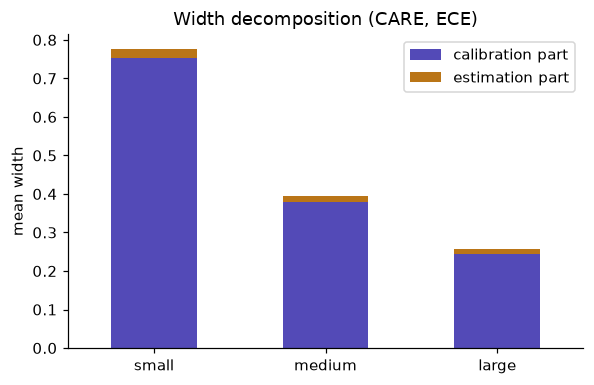

,calibration part,estimation part
small,0.753,0.023
medium,0.380,0.013
large,0.245,0.012


In [8]:
pt = I.parts(test, params["ece"])
size = test["syB"]; q1, q2 = np.quantile(size, [1/3, 2/3])
groups = {"small": size <= q1, "medium": (size > q1) & (size <= q2), "large": size > q2}
dec = pd.DataFrame({g: {"calibration part": pt["calibration"][m].mean(), "estimation part": pt["estimation"][m].mean()}
                    for g, m in groups.items()}).T
ax = dec.plot.bar(stacked=True, color=["#534AB7", "#BA7517"], figsize=(5.5, 3.6), rot=0)
ax.set(ylabel="mean width", title="Width decomposition (CARE, ECE)"); plt.tight_layout()
plt.savefig(ROOT / "results" / "decomposition.png"); plt.show(); dec

## 6. Tunability: coverage versus the requested confidence level

A good method stays at or above the diagonal (coverage >= level) at every level.

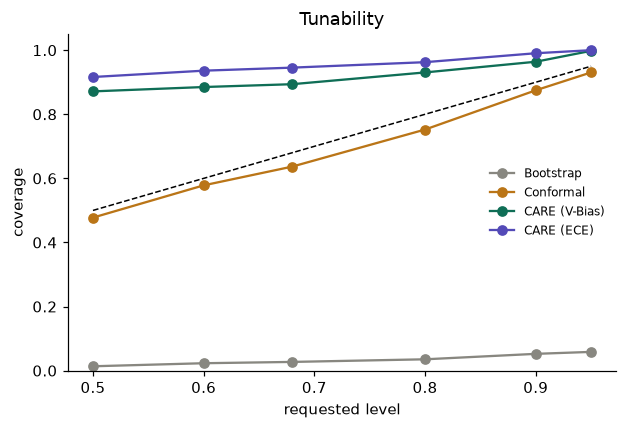

method,Bootstrap,Conformal,CARE (V-Bias),CARE (ECE)
level,,,,
0.50,0.014,0.478,0.871,0.916
0.60,0.023,0.578,0.885,0.936
0.68,0.027,0.637,0.894,0.946
0.80,0.035,0.752,0.931,0.963
0.90,0.052,0.875,0.964,0.990
0.95,0.059,0.931,0.998,1.000


In [9]:
levels = [0.5, 0.6, 0.68, 0.8, 0.9, 0.95]
tun = E.coverage_vs_level(stats, levels, n_repeats=30)
cov = tun.groupby(["method", "level"])["coverage"].mean().unstack(0)[methods]
ax = cov.plot(marker="o", color=[COLORS[m] for m in methods], figsize=(5.8, 4))
ax.plot([0.5, 0.95], [0.5, 0.95], "k--", lw=1); ax.set(xlabel="requested level", ylabel="coverage", title="Tunability", ylim=(0, 1.05))
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.savefig(ROOT / "results" / "tunability.png"); plt.show(); cov

## 7. What to write down

- Is the notebook running on **synthetic** or **real** statistics? (see the first output)
- Compare the coverage table with the paper's Table 1: bootstrap about 8-9%, conformal about 67%, CARE (V-Bias) about 87%, CARE (ECE) about 94% at level 0.68.
- Explain any gap: training length, voxel set, split scheme, calibration of the network. Do not tune anything to match the paper.
- Record settings in the deviation log of the guide (Part 8).